# Tugas Data Mining: Data Loading dan Eksplorasi Data

**Nama:** Sucitu Rahma Doah  
**NIM:** [241011450017]  
**Kelas:** [04TPLE001]

**Dataset:** Travel And Tourism (data pemesanan perjalanan wisata)  
**Jumlah data:** 1.000 baris dan 29 kolom  
**Referensi:** *Python for Data Analysis* (Wes McKinney), edisi 2022

**Tujuan tugas:**
1. Membagi jenis data (kategorikal dan numerikal).
2. Mengetahui tipe data pada kolom kategorikal.
3. Menghitung jumlah data duplicate dan null pada dataset.
4. Menentukan apakah penanganan outlier dan encoding data diperlukan (soal tambahan).

## 1. Data Loading

Tahap pertama yang dilakukan adalah membaca dataset ke dalam program. File dataset berformat **CSV**, sehingga dibaca dengan fungsi `read_csv` dari library **pandas**. Hasil pembacaan disimpan dalam variabel `df` yang bertipe DataFrame (tabel data).

In [1]:
# Mengimpor library pandas untuk mengolah data berbentuk tabel
import pandas as pd

# Membaca file CSV dan menyimpannya ke variabel dfs
df = pd.read_csv("Travel And Tourism.csv")

# Menampilkan 5 baris pertama untuk memastikan data berhasil dibaca
df.head()

,Booking_ID,Booking_Date,Travel_Date,Return_Date,Customer_ID,Customer_Name,Customer_Age,Gender,Customer_City,Customer_Country,...,Meal_Plan,Payment_Method,Booking_Status,Cancellation_Status,Cancellation_Reason,Discount_Amount,Customer_Rating,Customer_Review_Comment,Total_Trip_Cost,Transportation_Type
0,1,2026-02-23,2026-04-18,2026-04-21,cust01,Kenzo Vaughn,18,Male,Dubai,United Arab Emirates,...,Breakfast Included,Net Banking,Completed,Not Cancelled,Not Applicable,12800,1.0,Poor service experience,115000,Flight
1,2,2025-05-30,2025-06-29,2025-07-02,cust02,Priya Carter,20,Female,Udaipur,India,...,Full Board,Net Banking,Completed,Not Cancelled,Not Applicable,0,1.5,Poor service experience,56800,Train
2,3,2024-12-30,2025-03-14,2025-03-23,cust03,Elina Vaughn,31,Female,Dubai,United Arab Emirates,...,Full Board,UPI,Completed,Not Cancelled,Not Applicable,74400,2.0,Several arrangements need improvement,669800,Flight
3,4,2026-06-17,2026-09-19,2026-09-26,cust04,Mei Ferraro,30,Male,Kathmandu,Nepal,...,Room Only,Credit Card,Confirmed,Not Cancelled,Not Applicable,4500,0.0,Not yet travelled,84700,Flight
4,5,2025-03-21,2025-04-21,2025-04-24,cust05,Alina Desai,39,Female,Kuala Lumpur,Malaysia,...,Room Only,Digital Wallet,Completed,Not Cancelled,Not Applicable,2800,3.6,Good overall experience,15600,Flight


Tabel di atas menunjukkan 5 baris pertama dataset. Berikutnya dicek ukuran dataset untuk memastikan jumlah data memenuhi syarat minimal 1.000 baris.

In [2]:
# shape menampilkan (jumlah baris, jumlah kolom)
print("Ukuran dataset (baris, kolom):", df.shape)
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

Ukuran dataset (baris, kolom): (1000, 29)
Jumlah baris : 1000
Jumlah kolom : 29


**Penjelasan:** Dataset memiliki **1.000 baris** dan **29 kolom**, sehingga memenuhi syarat minimal 1.000 data.

## 2. Eksplorasi Data

Eksplorasi dilakukan untuk mengenal struktur data sebelum diproses dengan algoritma data mining.

In [3]:
# info() menampilkan nama kolom, jumlah data terisi (non-null), dan tipe data tiap kolom
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Booking_ID               1000 non-null   int64  
 1   Booking_Date             1000 non-null   str    
 2   Travel_Date              1000 non-null   str    
 3   Return_Date              1000 non-null   str    
 4   Customer_ID              1000 non-null   str    
 5   Customer_Name            1000 non-null   str    
 6   Customer_Age             1000 non-null   int64  
 7   Gender                   1000 non-null   str    
 8   Customer_City            1000 non-null   str    
 9   Customer_Country         1000 non-null   str    
 10  Destination_City         1000 non-null   str    
 11  Destination_Country      1000 non-null   str    
 12  Number_of_Travellers     1000 non-null   int64  
 13  Number_of_Adults         1000 non-null   int64  
 14  Number_of_Children       1000 non-nu

**Penjelasan:** Seluruh kolom berisi 1.000 data terisi (non-null). Kolom bertipe angka (`int64`, `float64`) adalah data numerikal, sedangkan kolom bertipe teks (`str`) adalah data kategorikal.

In [4]:
# describe() menampilkan ringkasan statistik untuk kolom numerikal:
# jumlah data, rata-rata, simpangan baku, nilai minimum, kuartil, dan maksimum
df.describe()

,Booking_ID,Customer_Age,Number_of_Travellers,Number_of_Adults,Number_of_Children,Hotel_Rating,Number_of_Rooms,Number_of_Nights,Discount_Amount,Customer_Rating,Total_Trip_Cost
count,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,500.500000,34.468000,5.6610,4.295000,1.366000,2.948600,2.959000,5.375000,15980.000000,2.315000,2.278389e+05
std,288.819436,9.327914,3.3189,2.342106,1.593293,1.299325,1.534821,2.262188,24817.542796,1.673941,2.268066e+05
min,1.000000,18.000000,1.0000,1.000000,0.000000,1.000000,1.000000,2.000000,0.000000,0.000000,1.100000e+04
25%,250.750000,26.000000,3.0000,2.000000,0.000000,1.800000,2.000000,3.000000,0.000000,1.000000,8.160000e+04
50%,500.500000,34.000000,5.0000,4.000000,1.000000,2.900000,3.000000,5.000000,7850.000000,2.300000,1.572000e+05
75%,750.250000,42.000000,8.0000,5.000000,3.000000,4.200000,4.000000,7.000000,20125.000000,3.900000,2.832500e+05
max,1000.000000,50.000000,15.0000,15.000000,7.000000,5.000000,8.000000,10.000000,289300.000000,5.000000,1.639200e+06


**Penjelasan:** Ringkasan statistik hanya tampil untuk kolom numerikal. Beberapa temuan:
- Usia pelanggan berkisar 18 sampai 50 tahun, rata-rata sekitar 34,5 tahun.
- Lama menginap berkisar 2 sampai 10 malam, rata-rata sekitar 5,4 malam.
- Rata-rata `Total_Trip_Cost` (sekitar 227.839) lebih besar dari mediannya (157.200), artinya sebaran biaya condong ke kanan karena ada beberapa pesanan yang sangat mahal.
- `Customer_Rating` bernilai minimum 0.0, yaitu pada pesanan yang belum berangkat (komentar "Not yet travelled").

## 3. Jawaban Pertanyaan

### Soal 1: Bagi jenis data (Data Kategorikal dan Data Numerikal)

- **Data numerikal**: berisi angka yang dapat dihitung (bertipe `int` atau `float`).
- **Data kategorikal**: berisi label atau kelompok (bertipe teks).

In [5]:
# Memilih kolom bertipe angka sebagai data numerikal
numerikal = df.select_dtypes(include="number").columns.tolist()

# Memilih kolom selain angka sebagai data kategorikal
kategorikal = df.select_dtypes(exclude="number").columns.tolist()

print("DATA NUMERIKAL:", len(numerikal), "kolom")
for k in numerikal:
    print(" -", k)

print()
print("DATA KATEGORIKAL:", len(kategorikal), "kolom")
for k in kategorikal:
    print(" -", k)

DATA NUMERIKAL: 11 kolom
 - Booking_ID
 - Customer_Age
 - Number_of_Travellers
 - Number_of_Adults
 - Number_of_Children
 - Hotel_Rating
 - Number_of_Rooms
 - Number_of_Nights
 - Discount_Amount
 - Customer_Rating
 - Total_Trip_Cost

DATA KATEGORIKAL: 18 kolom
 - Booking_Date
 - Travel_Date
 - Return_Date
 - Customer_ID
 - Customer_Name
 - Gender
 - Customer_City
 - Customer_Country
 - Destination_City
 - Destination_Country
 - Hotel_Name
 - Meal_Plan
 - Payment_Method
 - Booking_Status
 - Cancellation_Status
 - Cancellation_Reason
 - Customer_Review_Comment
 - Transportation_Type


**Jawaban:** Dataset memiliki **11 kolom numerikal** dan **18 kolom kategorikal**.

Catatan:
- `Booking_ID` bertipe angka, tetapi hanya berfungsi sebagai nomor pengenal, bukan data yang dihitung.
- `Booking_Date`, `Travel_Date`, dan `Return_Date` terbaca sebagai teks. Kolom tanggal ini sebaiknya diubah ke tipe tanggal (`datetime`) sebelum dianalisis lebih lanjut.
- `Customer_ID` dan `Customer_Name` bertipe teks dan berfungsi sebagai identitas pelanggan.

### Soal 2: Data kategorikal tuh pakai apa, float, void?

Tipe data kolom kategorikal dicek dengan atribut `dtypes`.

In [6]:
# dtypes menampilkan tipe data setiap kolom kategorikal
df[kategorikal].dtypes

Booking_Date               str
Travel_Date                str
Return_Date                str
Customer_ID                str
Customer_Name              str
Gender                     str
Customer_City              str
Customer_Country           str
Destination_City           str
Destination_Country        str
Hotel_Name                 str
Meal_Plan                  str
Payment_Method             str
Booking_Status             str
Cancellation_Status        str
Cancellation_Reason        str
Customer_Review_Comment    str
Transportation_Type        str
dtype: object

In [7]:
# Melihat isi (nilai unik) beberapa kolom kategorikal sebagai contoh
for kolom in ["Gender", "Meal_Plan", "Payment_Method", "Booking_Status", "Transportation_Type"]:
    print(kolom, "->", df[kolom].unique().tolist())

Gender -> ['Male', 'Female']
Meal_Plan -> ['Breakfast Included', 'Full Board', 'Room Only', 'Half Board']
Payment_Method -> ['Net Banking', 'UPI', 'Credit Card', 'Digital Wallet', 'Debit Card', 'EMI']
Booking_Status -> ['Completed', 'Confirmed', 'Cancelled', 'Pending']
Transportation_Type -> ['Flight', 'Train', 'Car']


**Jawaban:** Data kategorikal bertipe **`str` (string/teks)**, bukan `float` dan bukan `void`. Pada pandas versi lama, tipe ini tampil sebagai `object`. Tipe `float` dipakai untuk data numerikal berkoma (contoh: `Hotel_Rating`, `Customer_Rating`), sedangkan `void` bukan tipe data pada pandas.

### Soal 3: Berapa jumlah data yang duplicate dan null pada dataset

- **Duplicate**: baris yang isinya sama persis dengan baris lain.
- **Null**: sel yang kosong (tidak ada nilainya).

In [8]:
# duplicated() menandai baris yang sama persis dengan baris sebelumnya, sum() menjumlahkannya
print("Jumlah data duplicate:", df.duplicated().sum())

Jumlah data duplicate: 0


In [9]:
# isnull() menandai sel kosong, sum() menghitung jumlahnya per kolom
print("Jumlah null per kolom:")
print(df.isnull().sum())

# Total seluruh nilai null di dataset
print()
print("Total null:", df.isnull().sum().sum())

Jumlah null per kolom:
Booking_ID                 0
Booking_Date               0
Travel_Date                0
Return_Date                0
Customer_ID                0
Customer_Name              0
Customer_Age               0
Gender                     0
Customer_City              0
Customer_Country           0
Destination_City           0
Destination_Country        0
Number_of_Travellers       0
Number_of_Adults           0
Number_of_Children         0
Hotel_Name                 0
Hotel_Rating               0
Number_of_Rooms            0
Number_of_Nights           0
Meal_Plan                  0
Payment_Method             0
Booking_Status             0
Cancellation_Status        0
Cancellation_Reason        0
Discount_Amount            0
Customer_Rating            0
Customer_Review_Comment    0
Total_Trip_Cost            0
Transportation_Type        0
dtype: int64

Total null: 0


**Jawaban:** Jumlah data **duplicate = 0** dan jumlah data **null = 0**. Dataset sudah bersih dari data ganda dan nilai kosong.

Catatan: beberapa kolom memakai teks pengganti, bukan sel kosong, yaitu `Cancellation_Reason = "Not Applicable"` untuk pesanan yang tidak dibatalkan dan `Customer_Review_Comment = "Not yet travelled"` untuk pesanan yang belum berangkat. Nilai ini bukan null menurut pandas, tetapi perlu diperhatikan saat analisis.

### Soal 4 (tambahan): Apakah diperlukan penanganan outlier dan encoding data?

**Jawaban singkat:** Untuk tahap eksplorasi (soal 1 sampai 3), keduanya belum wajib. Namun untuk persiapan data sebelum masuk ke algoritma data mining, keduanya **diperlukan**. Berikut pembuktiannya pada dataset ini.

- **Outlier**: nilai yang sangat jauh dari sebagian besar data. Dideteksi dengan metode **IQR** (nilai di luar `Q1 - 1.5 x IQR` dan `Q3 + 1.5 x IQR`).
- **Encoding**: mengubah data kategorikal (teks) menjadi angka, karena sebagian besar algoritma data mining hanya bisa memproses angka.

#### 4.1 Deteksi outlier

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Booking_ID tidak diperiksa karena hanya nomor pengenal
kolom_numerikal = df.select_dtypes(include="number").columns.drop("Booking_ID")

batas = {}
hasil = []
for k in kolom_numerikal:
    q1 = df[k].quantile(0.25)
    q3 = df[k].quantile(0.75)
    iqr = q3 - q1
    bawah = q1 - 1.5 * iqr
    atas = q3 + 1.5 * iqr
    batas[k] = (bawah, atas)
    jumlah = int(((df[k] < bawah) | (df[k] > atas)).sum())
    hasil.append({"Kolom": k, "Q1": q1, "Q3": q3,
                  "Batas_Bawah": bawah, "Batas_Atas": atas,
                  "Jumlah_Outlier": jumlah})

tabel_outlier = pd.DataFrame(hasil)
tabel_outlier

,Kolom,Q1,Q3,Batas_Bawah,Batas_Atas,Jumlah_Outlier
0,Customer_Age,26.0,42.0,2.00,66.00,0
1,Number_of_Travellers,3.0,8.0,-4.50,15.50,0
2,Number_of_Adults,2.0,5.0,-2.50,9.50,59
3,Number_of_Children,0.0,3.0,-4.50,7.50,0
4,Hotel_Rating,1.8,4.2,-1.80,7.80,0
5,Number_of_Rooms,2.0,4.0,-1.00,7.00,1
6,Number_of_Nights,3.0,7.0,-3.00,13.00,0
7,Discount_Amount,0.0,20125.0,-30187.50,50312.50,74
8,Customer_Rating,1.0,3.9,-3.35,8.25,0
9,Total_Trip_Cost,81600.0,283250.0,-220875.00,585725.00,75


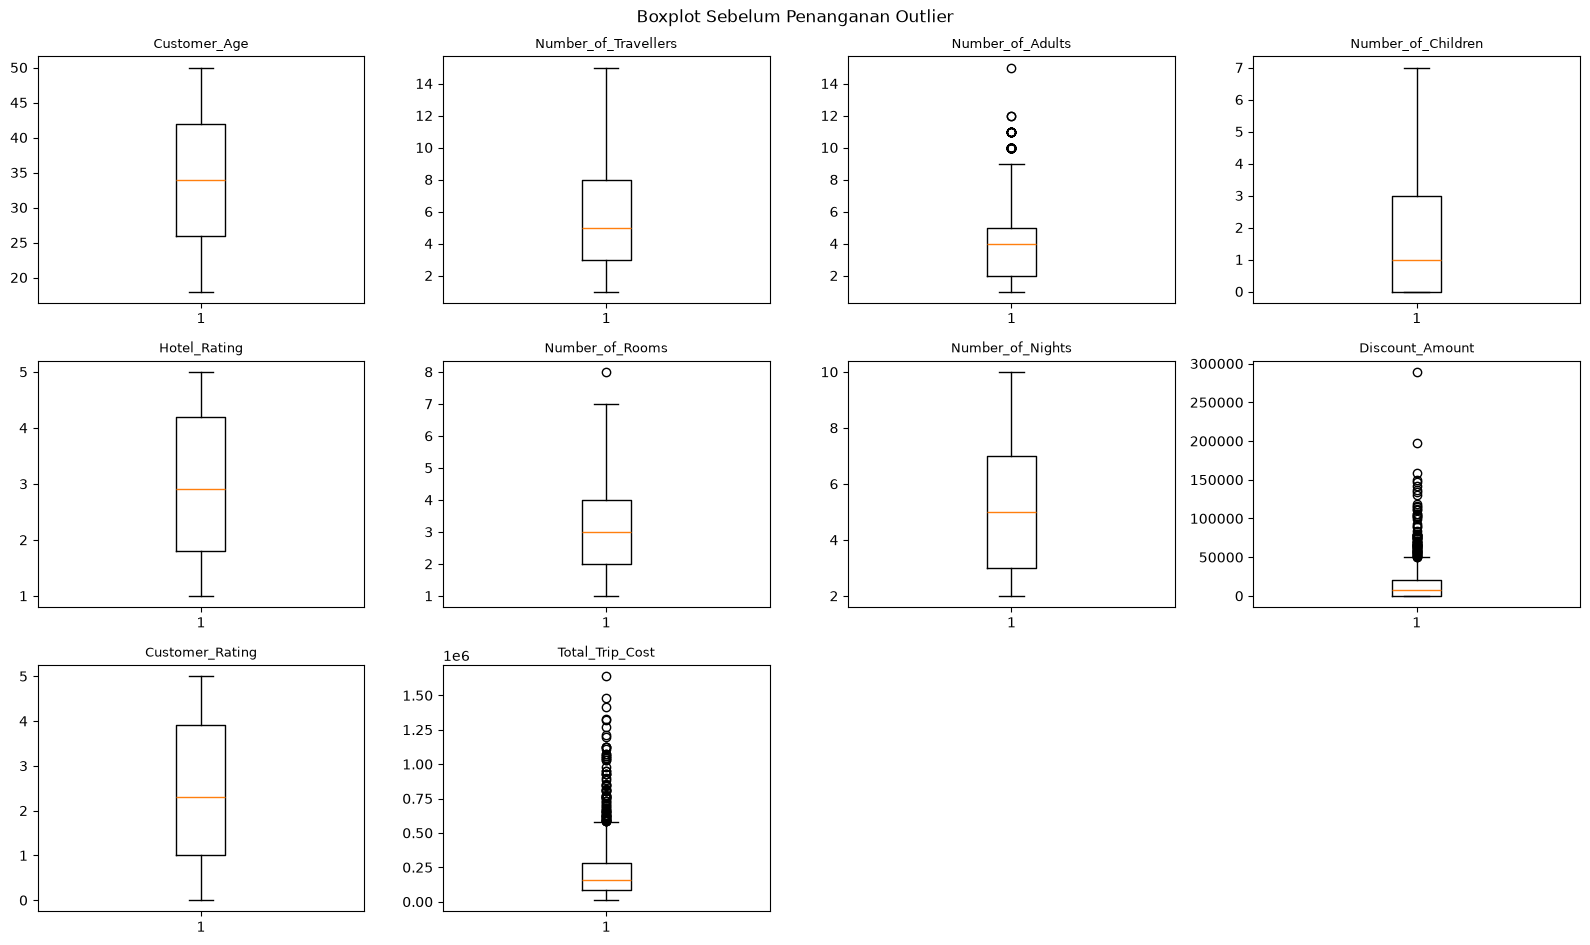

In [11]:
# Boxplot sebelum penanganan: titik di luar kotak/whisker adalah outlier
n = len(kolom_numerikal)
baris = int(np.ceil(n / 4))
fig, axes = plt.subplots(baris, 4, figsize=(16, 3.2 * baris))
axes = axes.flatten()

for i, k in enumerate(kolom_numerikal):
    axes[i].boxplot(df[k])
    axes[i].set_title(k, fontsize=9)
for j in range(n, len(axes)):
    axes[j].axis("off")

plt.suptitle("Boxplot Sebelum Penanganan Outlier")
plt.tight_layout()
plt.show()

**Penjelasan:** Outlier ditemukan pada 4 kolom: `Number_of_Adults` (59 data), `Number_of_Rooms` (1 data), `Discount_Amount` (74 data), dan `Total_Trip_Cost` (75 data). Kolom lain tidak memiliki outlier.

#### 4.2 Penanganan outlier

Outlier **tidak dihapus** karena biaya tinggi atau rombongan besar masih wajar pada data wisata (misalnya perjalanan mewah). Penghapusan juga akan mengurangi jumlah data di bawah 1.000 baris. Karena itu dipakai **capping**: nilai di luar batas diganti dengan nilai batas IQR.

In [12]:
df_clean = df.copy()
kolom_outlier = tabel_outlier.loc[tabel_outlier["Jumlah_Outlier"] > 0, "Kolom"].tolist()
print("Kolom yang punya outlier:", kolom_outlier)

for k in kolom_outlier:
    bawah, atas = batas[k]
    df_clean[k] = df_clean[k].clip(lower=bawah, upper=atas)
    if k.startswith("Number_of"):
        df_clean[k] = df_clean[k].round().astype(int)  # jumlah orang/kamar harus bilangan bulat

# Perbandingan nilai maksimum sebelum dan sesudah capping
pd.DataFrame({"Max_Sebelum": df[kolom_outlier].max(),
              "Max_Sesudah": df_clean[kolom_outlier].max()})

Kolom yang punya outlier: ['Number_of_Adults', 'Number_of_Rooms', 'Discount_Amount', 'Total_Trip_Cost']


,Max_Sebelum,Max_Sesudah
Number_of_Adults,15,10.0
Number_of_Rooms,8,7.0
Discount_Amount,289300,50312.5
Total_Trip_Cost,1639200,585725.0


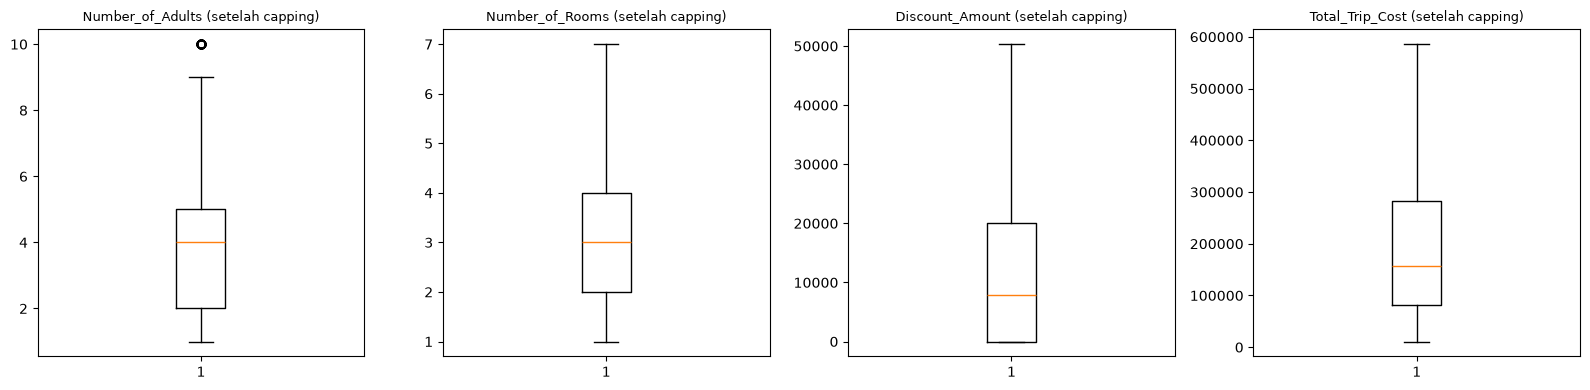

In [13]:
# Boxplot setelah capping
fig, axes = plt.subplots(1, len(kolom_outlier), figsize=(4 * len(kolom_outlier), 4))
for ax, k in zip(axes, kolom_outlier):
    ax.boxplot(df_clean[k])
    ax.set_title(k + " (setelah capping)", fontsize=9)
plt.tight_layout()
plt.show()

**Penjelasan:** Setelah capping, nilai ekstrem sudah dibatasi dan jumlah data tetap 1.000 baris. Untuk `Number_of_Adults`, batas atas 9,5 dibulatkan menjadi 10 karena jumlah orang harus bilangan bulat.

#### 4.3 Encoding data

- **Label/ordinal encoding** dipakai untuk kolom dengan 2 nilai atau yang punya urutan. `Meal_Plan` memakai ordinal karena tingkat layanannya berurutan (Room Only < Breakfast Included < Half Board < Full Board).
- **One-hot encoding** dipakai untuk kolom nominal yang tidak punya urutan, yaitu `Payment_Method`, `Booking_Status`, dan `Transportation_Type`.

In [14]:
df_enc = df_clean.copy()

# Label / ordinal encoding
df_enc["Gender_Encoded"] = df_enc["Gender"].map({"Male": 0, "Female": 1})
df_enc["Cancellation_Status_Encoded"] = df_enc["Cancellation_Status"].map(
    {"Not Cancelled": 0, "Cancelled": 1})
df_enc["Meal_Plan_Encoded"] = df_enc["Meal_Plan"].map(
    {"Room Only": 0, "Breakfast Included": 1, "Half Board": 2, "Full Board": 3})

df_enc[["Gender", "Gender_Encoded",
        "Cancellation_Status", "Cancellation_Status_Encoded",
        "Meal_Plan", "Meal_Plan_Encoded"]].head()

,Gender,Gender_Encoded,Cancellation_Status,Cancellation_Status_Encoded,Meal_Plan,Meal_Plan_Encoded
0,Male,0,Not Cancelled,0,Breakfast Included,1
1,Female,1,Not Cancelled,0,Full Board,3
2,Female,1,Not Cancelled,0,Full Board,3
3,Male,0,Not Cancelled,0,Room Only,0
4,Female,1,Not Cancelled,0,Room Only,0


In [15]:
# One-hot encoding
kolom_onehot = ["Payment_Method", "Booking_Status", "Transportation_Type"]
df_enc = pd.get_dummies(df_enc, columns=kolom_onehot, dtype=int)

print("Ukuran data setelah encoding:", df_enc.shape)
df_enc.head()

Ukuran data setelah encoding: (1000, 42)


,Booking_ID,Booking_Date,Travel_Date,Return_Date,Customer_ID,Customer_Name,Customer_Age,Gender,Customer_City,Customer_Country,...,Payment_Method_EMI,Payment_Method_Net Banking,Payment_Method_UPI,Booking_Status_Cancelled,Booking_Status_Completed,Booking_Status_Confirmed,Booking_Status_Pending,Transportation_Type_Car,Transportation_Type_Flight,Transportation_Type_Train
0,1,2026-02-23,2026-04-18,2026-04-21,cust01,Kenzo Vaughn,18,Male,Dubai,United Arab Emirates,...,0,1,0,0,1,0,0,0,1,0
1,2,2025-05-30,2025-06-29,2025-07-02,cust02,Priya Carter,20,Female,Udaipur,India,...,0,1,0,0,1,0,0,0,0,1
2,3,2024-12-30,2025-03-14,2025-03-23,cust03,Elina Vaughn,31,Female,Dubai,United Arab Emirates,...,0,0,1,0,1,0,0,0,1,0
3,4,2026-06-17,2026-09-19,2026-09-26,cust04,Mei Ferraro,30,Male,Kathmandu,Nepal,...,0,0,0,0,0,1,0,0,1,0
4,5,2025-03-21,2025-04-21,2025-04-24,cust05,Alina Desai,39,Female,Kuala Lumpur,Malaysia,...,0,0,0,0,1,0,0,0,1,0


**Jawaban:** Penanganan outlier dan encoding data **diperlukan sebelum pemodelan**, tetapi bukan bagian dari tahap eksplorasi. Outlier pada `Total_Trip_Cost` dan `Discount_Amount` dapat mengganggu algoritma berbasis jarak dan rata-rata, sedangkan kolom teks harus diubah menjadi angka agar bisa diproses algoritma. Kolom seperti `Customer_Name`, `Customer_City`, dan `Hotel_Name` tidak di-encode karena berupa pengenal atau memiliki terlalu banyak nilai unik.

## 4. Eksplorasi Tambahan

In [16]:
# Jumlah pesanan berdasarkan status booking
df["Booking_Status"].value_counts()

Booking_Status
Completed    772
Cancelled    141
Confirmed     79
Pending        8
Name: count, dtype: int64

In [17]:
# 10 negara tujuan yang paling banyak dipesan
df["Destination_Country"].value_counts().head(10)

Destination_Country
India                   669
Sri Lanka                49
Indonesia                44
United Arab Emirates     42
United Kingdom           41
Thailand                 35
Nepal                    34
Maldives                 32
France                   29
Singapore                25
Name: count, dtype: int64

In [18]:
# Rata-rata total biaya perjalanan berdasarkan jenis transportasi
df.groupby("Transportation_Type")["Total_Trip_Cost"].mean().round(0)

Transportation_Type
Car       111257.0
Flight    274970.0
Train     137759.0
Name: Total_Trip_Cost, dtype: float64

## 5. Kesimpulan

1. Dataset **Travel And Tourism** berisi **1.000 baris** dan **29 kolom**, sehingga memenuhi syarat minimal 1.000 data.
2. Terdapat **11 kolom numerikal** dan **18 kolom kategorikal**. Kolom kategorikal bertipe teks (`str`).
3. Dataset tidak memiliki data **duplicate** maupun **null** (keduanya berjumlah 0).
4. Outlier ditemukan pada `Number_of_Adults`, `Number_of_Rooms`, `Discount_Amount`, dan `Total_Trip_Cost`, ditangani dengan capping IQR tanpa mengurangi jumlah data. Kolom kategorikal di-encode (ordinal dan one-hot) sebagai persiapan sebelum pemodelan.
5. Tahap mengenal data (data loading dan eksplorasi) ini menjadi dasar sebelum memilih algoritma data mining yang sesuai pada pertemuan berikutnya.